<a href="https://colab.research.google.com/github/quarcs-lab/gdo4bolivia/blob/main/notebooks/embeddings_mpi_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting multidimensional poverty from satellite embeddings

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/gdo4bolivia/).

Can satellite imagery predict poverty where surveys are missing? This notebook trains machine-learning models to predict the **Multidimensional Poverty Index** (`sdg1_2_mpi`, 0–1; **higher = poorer**) of Bolivia's municipalities from the 64 dimensions of Google's **satellite embeddings** (`emb` and `embpw`, 2017), and compares them with a baseline built on **night-time lights and population**. The poverty index comes from the *Atlas de los ODS en Bolivia 2026* (SDSN Bolivia), computed from the population censuses of **2012 and 2024**, so the same imagery is used to predict poverty at both dates.

Outline:

1. **Load** the targets and the features with [`geo4bolivia`](https://quarcs-lab.github.io/geo4bolivia/)
2. **Models and validation**: random forest and XGBoost; random 5-fold and spatial (leave-one-department-out) cross-validation
3. **Comparison table**: R², RMSE and MAE, for each census
4. **Feature importance**: the top 20 embedding dimensions
5. **Predicted vs observed**
6. **Where the model fails**: maps of out-of-fold residuals (`geo.map`) and their spatial autocorrelation (`geo.moran`)

It builds on DS4Bolivia's `run_poverty_prediction.py` script, with different targets, a spatial validation and a lights baseline.

**Why 339 municipalities.** The poverty index follows SDSN Bolivia's 2025 map of **343** municipalities and indigenous autonomies (GAIOC), `map343`. The embeddings, lights and population were computed by DS4Bolivia on the polygons of the older 2015 map, so they are published on that map, `map339`, for its **339 municipalities**. The two maps share geo IDs: the 339 municipalities kept theirs in 2025. Four units were created after 2012 (TIOC-Raqaypampa, San Pedro de Macha, TIOC-Jatun Ayllu Yura and TIOC-Territorio Indígena Multiétnico) and have no features; the six municipalities they were carved from (Mizque, Colquechaca, Porco, Tomave, San Ignacio and Santa Ana) keep features that describe their 2015 territory. The models use the 339 units with both, and the spatial checks use the 2015 map (`map="map339"`), the polygons the features belong to.

**A caveat on timing.** The embeddings summarise imagery of **2017**, which lies between the two censuses: five years after 2012 and seven before 2024. The models therefore predict poverty from a landscape observed at a different date. Settlements, roads and land cover change slowly, so the embeddings still carry information about living conditions at both dates, but the mismatch is a limitation. The lights and population baseline is aligned as closely as the data allow: 2012 for the 2012 target and 2020, the latest year available, for the 2024 target.

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds): the `geo4bolivia` package, which loads the data, draws the maps and tests the residuals for spatial autocorrelation. Colab already has scikit-learn and XGBoost. Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

needs = {"geo4bolivia": "geo4bolivia", "sklearn": "scikit-learn", "xgboost": "xgboost"}   # module: package
missing = [package for module, package in needs.items() if importlib.util.find_spec(module) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import geo4bolivia as geo
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

SEED = 42

## 1. Load the targets and the features

Everything is keyed by `geo_id`. The poverty index is stored at two nominal years, 2012 and 2024, the years of the two censuses. `wide=` gives one row per municipality with one column per year, and `groups=` adds the name of each municipality and of its department. The two embedding datasets have the same column names (`A00`–`A63`), so we load them separately rather than with `geo.combine` (which would prefix them `emb_` and `embpw_`):

- **`emb`**: each dimension averaged over the municipality's area
- **`embpw`**: each dimension averaged with population weights, so it describes the places where people live

In [3]:
TARGETS = [2012, 2024]
LIGHTS_YEAR = {2012: 2012, 2024: 2020}      # lights and population: latest year <= target

mpi = geo.load("sdg01", variables="sdg1_2_mpi", wide="sdg1_2_mpi", groups=["department"])
ntl = geo.load("ntl", variables="ln_t400NTLpc", wide="ln_t400NTLpc")
pop = geo.load("pop", variables="pop", wide="pop")
emb = geo.load("emb", years=2017).set_index("geo_id")
embpw = geo.load("embpw", years=2017).set_index("geo_id")

print("Units with MPI:", mpi["geo_id"].nunique(), "| with embeddings:", emb.index.nunique(),
      "| with lights:", ntl["geo_id"].nunique())

df = (mpi.merge(ntl, on="geo_id").merge(pop, on="geo_id")
         .merge(emb[[]], left_on="geo_id", right_index=True))         # keep units with embeddings
for t in TARGETS:
    df[f"ln_pop{LIGHTS_YEAR[t]}"] = np.log(df[f"pop{LIGHTS_YEAR[t]}"])

DIMS = [f"A{i:02d}" for i in range(64)]
X_emb = emb.loc[df["geo_id"], DIMS].to_numpy()
X_embpw = embpw.loc[df["geo_id"], DIMS].to_numpy()
y = {t: df[f"sdg1_2_mpi{t}"].to_numpy() for t in TARGETS}
groups = df["department"].to_numpy()

print("Sample:", len(df), "municipalities | missing values:",
      int(df.filter(regex="sdg1_2_mpi|ln_t400NTLpc|ln_pop").isna().sum().sum()),
      int(np.isnan(X_emb).sum()), int(np.isnan(X_embpw).sum()))
for t in TARGETS:
    print(f"MPI {t}: mean {y[t].mean():.3f}, sd {y[t].std():.3f}, range {y[t].min():.3f}-{y[t].max():.3f}")
print(f"Correlation of MPI 2012 with MPI 2024: {np.corrcoef(y[2012], y[2024])[0, 1]:.2f}")

Units with MPI: 343 | with embeddings: 339 | with lights: 339
Sample: 339 municipalities | missing values: 0 0 0
MPI 2012: mean 0.232, sd 0.103, range 0.018-0.541
MPI 2024: mean 0.062, sd 0.042, range 0.003-0.223
Correlation of MPI 2012 with MPI 2024: 0.86


Among the 339 units, mean poverty fell from 0.232 in 2012 to 0.062 in 2024, and its standard deviation from 0.103 to 0.042, so the 2024 target has a much smaller variance. The ordering of municipalities changed less: the two targets are correlated at 0.86. R² (the share of each target's own variance explained) is comparable across the two targets; RMSE and MAE are not.

The four feature sets, for each target (the lights and population columns change with the target year):

In [4]:
def feature_sets(t):
    lp = [f"ln_t400NTLpc{LIGHTS_YEAR[t]}", f"ln_pop{LIGHTS_YEAR[t]}"]
    return {
        "Lights + population":               df[lp].to_numpy(),
        "Embeddings, area-weighted":         X_emb,
        "Embeddings, population-weighted":   X_embpw,
        "Pop.-weighted embeddings + lights": np.column_stack([X_embpw, df[lp]]),
    }

FEATURE_SETS = list(feature_sets(2012))
{k: v.shape for k, v in feature_sets(2024).items()}

{'Lights + population': (339, 2),
 'Embeddings, area-weighted': (339, 64),
 'Embeddings, population-weighted': (339, 64),
 'Pop.-weighted embeddings + lights': (339, 66)}

## 2. Models and validation

Two tree ensembles, with fixed seeds:

- **Random forest**: the configuration of DS4Bolivia's script (500 trees, depth up to 10, `sqrt` features per split)
- **XGBoost**: 400 shallow boosted trees with a small learning rate and row/column subsampling

Every municipality is predicted **out of fold**, by a model that did not see it during training, under two designs:

- **Random 5-fold CV**: municipalities are shuffled into 5 folds. Neighbours of a test municipality are usually in the training set, so this measures *interpolation* within regions the model knows.
- **Spatial CV by department**: `GroupKFold` with the 9 departments as groups, i.e. leave one department out. The model must predict a whole department it has never seen, a much harder and more honest test of *transfer* to new regions.

The metrics are computed on the pooled out-of-fold predictions of all 339 municipalities: 2 targets × 4 feature sets × 2 models × 2 designs = 32 cross-validations.

In [5]:
def make_models():
    return {
        "Random forest": RandomForestRegressor(
            n_estimators=500, max_depth=10, min_samples_split=5, min_samples_leaf=2,
            max_features="sqrt", random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(
            n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=3,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=SEED, n_jobs=4, verbosity=0),
    }

cv_designs = {
    "Random 5-fold": (KFold(n_splits=5, shuffle=True, random_state=SEED), None),
    "Spatial (by department)": (GroupKFold(n_splits=9), groups),
}

def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred)}

start = time.time()
rows, oof = [], {}
for t in TARGETS:
    for fs_name, X in feature_sets(t).items():
        for model_name, model in make_models().items():
            for cv_name, (cv, g) in cv_designs.items():
                pred = cross_val_predict(model, X, y[t], cv=cv, groups=g)
                oof[(t, fs_name, model_name, cv_name)] = pred
                rows.append({"target": f"MPI {t}", "features": fs_name, "model": model_name,
                             "cv": cv_name, **metrics(y[t], pred)})
print(f"{len(rows)} cross-validations in {time.time() - start:.0f} s")
results = pd.DataFrame(rows)

32 cross-validations in 188 s


## 3. Comparison table

In [6]:
table = (results.pivot_table(index=["target", "features", "model"], columns="cv",
                             values=["R2", "RMSE", "MAE"])
                .swaplevel(0, 1, axis=1)
                .reindex(columns=pd.MultiIndex.from_product([list(cv_designs), ["R2", "RMSE", "MAE"]]))
                .reindex(FEATURE_SETS, level=1))
table.round(3)

Random 5-fold         \
                                                                    R2   RMSE   
target   features                          model                                
MPI 2012 Lights + population               Random forest         0.384  0.081   
                                           XGBoost               0.306  0.086   
         Embeddings, area-weighted         Random forest         0.324  0.085   
                                           XGBoost               0.352  0.083   
         Embeddings, population-weighted   Random forest         0.502  0.073   
                                           XGBoost               0.547  0.070   
         Pop.-weighted embeddings + lights Random forest         0.563  0.068   
                                           XGBoost               0.635  0.062   
MPI 2024 Lights + population               Random forest         0.198  0.037   
                                           XGBoost               0.121  0.039   
         Embeddings, area-weighted         Random forest         0.310  0.035   
                                           XGBoost               0.337  0.034   
         Embeddings, population-weighted   Random forest         0.434  0.031   
                                           XGBoost               0.459  0.031   
         Pop.-weighted embeddings + lights Random forest         0.477  0.030   
                                           XGBoost               0.519  0.029   

                                                                 \
                                                            MAE   
target   features                          model                  
MPI 2012 Lights + population               Random forest  0.064   
                                           XGBoost        0.068   
         Embeddings, area-weighted         Random forest  0.067   
                                           XGBoost        0.064   
         Embeddings, population-weighted   Random forest  0.057   
                                           XGBoost        0.053   
         Pop.-weighted embeddings + lights Random forest  0.054   
                                           XGBoost        0.049   
MPI 2024 Lights + population               Random forest  0.027   
                                           XGBoost        0.029   
         Embeddings, area-weighted         Random forest  0.026   
                                           XGBoost        0.025   
         Embeddings, population-weighted   Random forest  0.024   
                                           XGBoost        0.022   
         Pop.-weighted embeddings + lights Random forest  0.023   
                                           XGBoost        0.021   

                                                         Spatial (by department)  \
                                                                              R2   
target   features                          model                                   
MPI 2012 Lights + population               Random forest                   0.211   
                                           XGBoost                         0.010   
         Embeddings, area-weighted         Random forest                   0.026   
                                           XGBoost                         0.059   
         Embeddings, population-weighted   Random forest                   0.206   
                                           XGBoost                         0.205   
         Pop.-weighted embeddings + lights Random forest                   0.313   
                                           XGBoost                         0.324   
MPI 2024 Lights + population               Random forest                   0.012   
                                           XGBoost                        -0.032   
         Embeddings, area-weighted         Random forest                   0.009   
                                           XGBoost                 

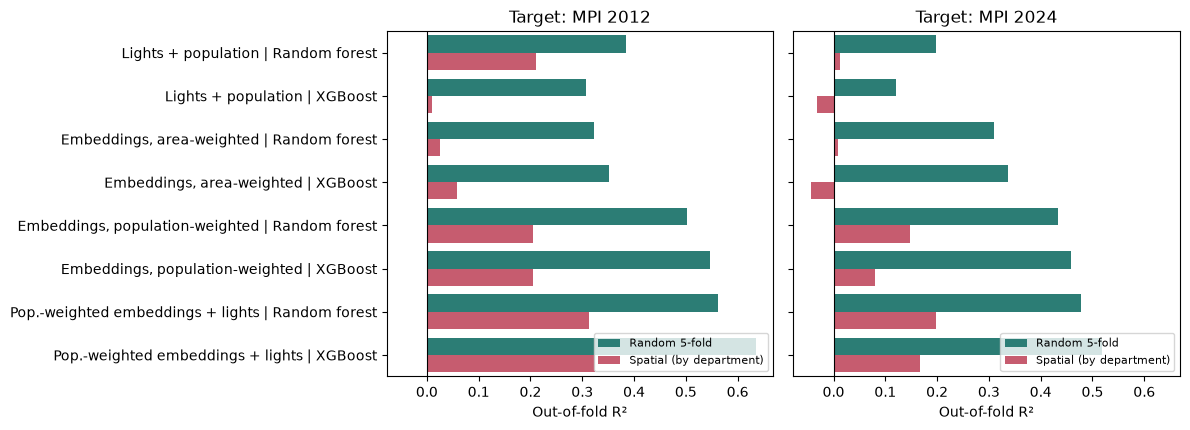

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, t in zip(axes, TARGETS):
    sub = results[results["target"] == f"MPI {t}"]
    sub = sub.assign(label=sub["features"] + " | " + sub["model"])
    sns.barplot(data=sub, y="label", x="R2", hue="cv", ax=ax, palette=["#1f8a80", "#d84a64"])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Target: MPI {t}")
    ax.set_xlabel("Out-of-fold R²")
    ax.set_ylabel("")
    ax.legend(title="", loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Random 5-fold CV, MPI 2012.**

- The lights-and-population baseline explains about a third of the variance in poverty with the random forest (R² 0.38) and less with XGBoost (0.31).
- Area-weighted embeddings do no better (0.32–0.35).
- **Population-weighted embeddings do much better** (0.50–0.55, RMSE 0.070–0.073 against 0.081 for the random-forest baseline). Averaging the imagery where people live, rather than over forests, salt flats and mountains, is what makes the embeddings informative about living conditions.
- Adding lights and population to them gives the best fit: **R² 0.64 with XGBoost** (RMSE 0.062, MAE 0.049) and 0.56 with the random forest.

**Random 5-fold CV, MPI 2024.** The ranking of the feature sets is the same, at lower levels.

- Lights and population (2020) carry little information about poverty in 2024 (R² 0.20 with the random forest, 0.12 with XGBoost).
- Area-weighted embeddings reach 0.31–0.34, population-weighted ones 0.43–0.46, and with lights and population **0.52 with XGBoost** (RMSE 0.029, MAE 0.021) and 0.48 with the random forest.

**Spatial CV (leave one department out).** Every model loses most of its accuracy.

- For 2012 the best is XGBoost with population-weighted embeddings and lights (R² 0.32, RMSE 0.085), closely followed by the random forest (0.31). Population-weighted embeddings alone and the random-forest baseline reach about 0.21; area-weighted embeddings only 0.03–0.06, and the XGBoost baseline 0.01.
- For 2024 the best is the random forest with population-weighted embeddings and lights (R² 0.20, RMSE 0.037), against 0.17 for XGBoost. Area-weighted embeddings explain nothing (−0.04 to 0.01) and the lights baseline is no better (0.01 and −0.03), so it predicts an unseen department no better than the national mean would.
- Much of what the models learn under random CV is therefore regional: they recognise the poverty level of a department from its neighbours in the training set, and that knowledge does not transfer to a department they have never seen.

The two algorithms perform similarly. XGBoost is better under random CV with every embedding set, while under spatial CV the lead changes with the target; neither was tuned.

## 4. Feature importance

Which embedding dimensions matter? For each target we refit both models on all 339 municipalities with the population-weighted embeddings and rank the 64 dimensions by the random forest's impurity importance and XGBoost's gain. The dimensions are abstract features learned from imagery, not named land-cover classes, so they are best read as "which parts of the embedding space separate poor from less-poor municipalities".

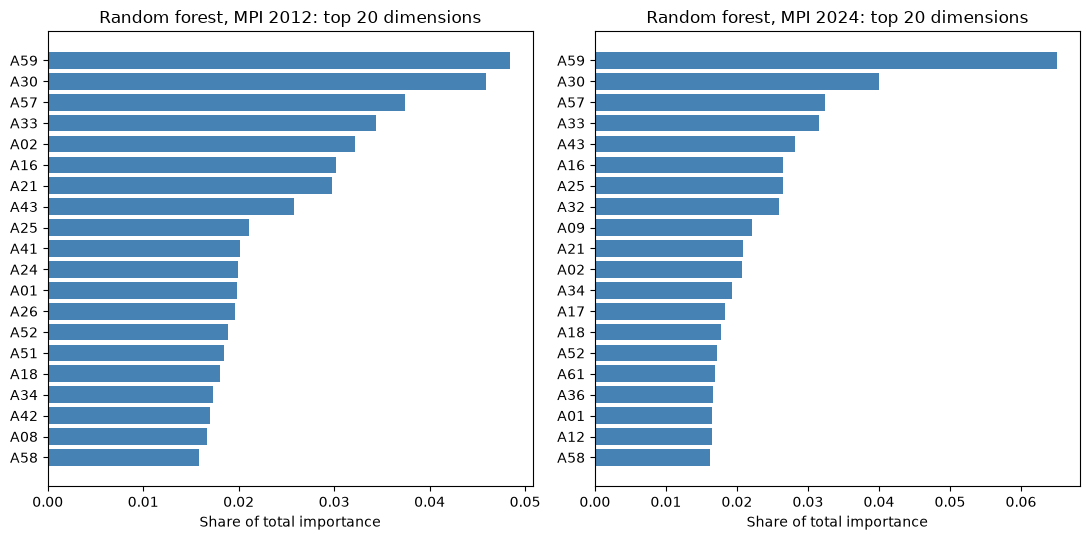

MPI 2012, Random forest: top 5 = A59, A30, A57, A33, A02 (first 4.8%); 43 of 64 dimensions reach 80%
MPI 2012, XGBoost: top 5 = A30, A02, A57, A59, A33 (first 5.7%); 39 of 64 dimensions reach 80%
MPI 2024, Random forest: top 5 = A59, A30, A57, A33, A43 (first 6.5%); 44 of 64 dimensions reach 80%
MPI 2024, XGBoost: top 5 = A59, A57, A32, A30, A33 (first 6.4%); 38 of 64 dimensions reach 80%
MPI 2012: 14 dimensions in both top-20 lists; correlation of the RF top 5 with MPI: {'A59': 0.38, 'A30': 0.44, 'A57': -0.35, 'A33': 0.35, 'A02': -0.3}
MPI 2024: 14 dimensions in both top-20 lists; correlation of the RF top 5 with MPI: {'A59': 0.42, 'A30': 0.37, 'A57': -0.32, 'A33': 0.33, 'A43': -0.36}
Random-forest top-20 dimensions shared by the two targets: 14


In [8]:
X_imp = X_embpw
importance = {}
for t in TARGETS:
    for name, m in make_models().items():
        m.fit(X_imp, y[t])
        importance[(t, name)] = m.feature_importances_ / m.feature_importances_.sum()
importance = pd.DataFrame(importance, index=DIMS)       # shares of total importance

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, t in zip(axes, TARGETS):
    top = importance[(t, "Random forest")].nlargest(20)[::-1]
    ax.barh(top.index, top.values, color="steelblue")
    ax.set_title(f"Random forest, MPI {t}: top 20 dimensions")
    ax.set_xlabel("Share of total importance")
plt.tight_layout()
plt.show()

emb_df = pd.DataFrame(X_imp, columns=DIMS)
for (t, name), imp in importance.items():
    cum = imp.sort_values(ascending=False).cumsum()
    print(f"MPI {t}, {name}: top 5 = {', '.join(cum.index[:5])} "
          f"(first {cum.iloc[0] * 100:.1f}%); {(cum < 0.8).sum() + 1} of 64 dimensions reach 80%")
for t in TARGETS:
    both = (set(importance[(t, "Random forest")].nlargest(20).index)
            & set(importance[(t, "XGBoost")].nlargest(20).index))
    corr = emb_df[importance[(t, "Random forest")].nlargest(5).index].corrwith(pd.Series(y[t]))
    print(f"MPI {t}: {len(both)} dimensions in both top-20 lists; "
          f"correlation of the RF top 5 with MPI: {corr.round(2).to_dict()}")
top20 = {t: set(importance[(t, "Random forest")].nlargest(20).index) for t in TARGETS}
print("Random-forest top-20 dimensions shared by the two targets:", len(top20[2012] & top20[2024]))

Two dimensions lead for both targets and both models: **A59** (first for the random forest in both years and for XGBoost in 2024, with 4.8–6.5% of the importance) and **A30** (first for XGBoost in 2012). Both are positively correlated with poverty (A59 +0.38 in 2012 and +0.42 in 2024; A30 +0.44 and +0.37). Beyond them, importance is spread thinly:

- 43–44 (random forest) and 38–39 (XGBoost) of the 64 dimensions are needed to reach 80% of the total importance.
- 14 dimensions appear in both models' top-20 lists in each year, and 14 of the random forest's top 20 are the same for the two targets: the same parts of the embedding space separate poorer from less-poor municipalities in 2012 and in 2024.

No small subset of dimensions carries the signal. Impurity and gain importances are also unstable when features are correlated, as embedding dimensions are, so the ranks beyond the first few are indicative only.

## 5. Predicted vs observed

We show the feature set and algorithm with the best average R² over both targets and both designs.

Model shown: XGBoost with Pop.-weighted embeddings + lights


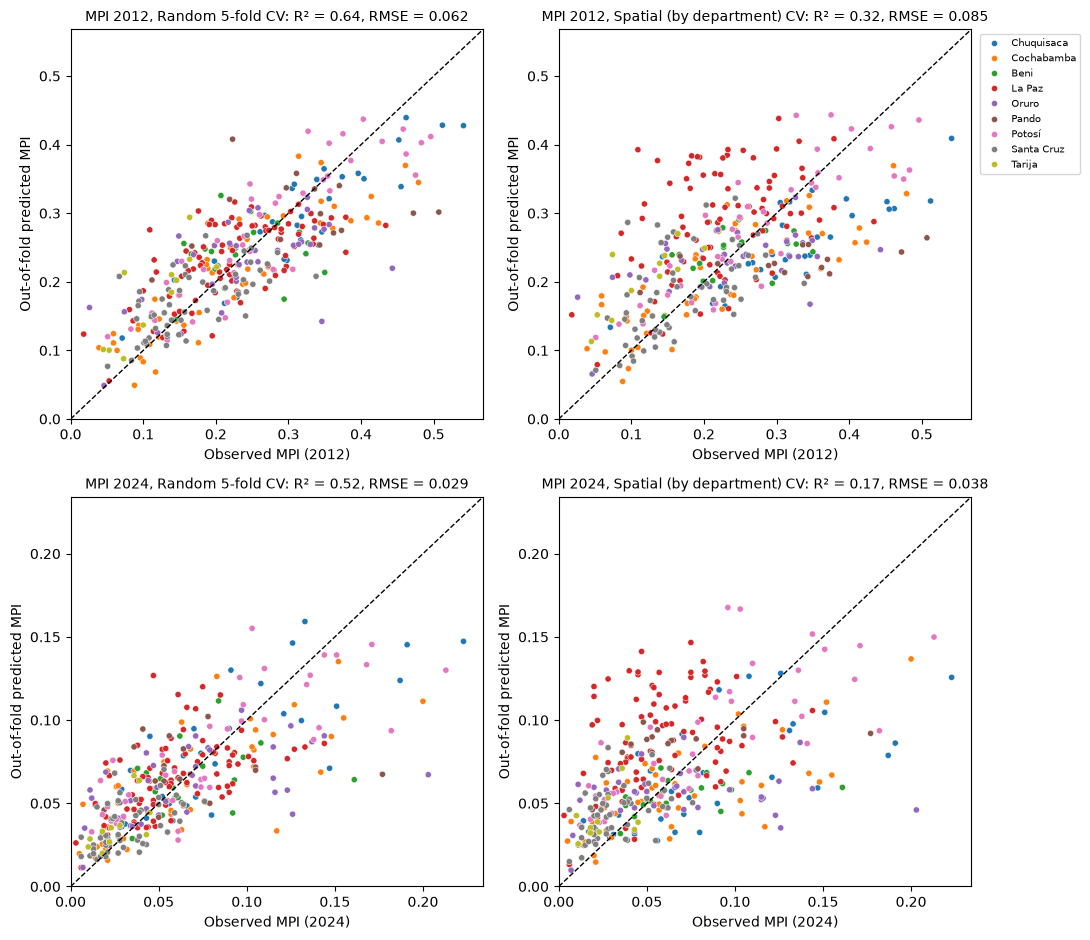

In [9]:
BEST_FEATURES = "Pop.-weighted embeddings + lights"
best_model = (results[results["features"] == BEST_FEATURES]
              .groupby("model")["R2"].mean().idxmax())
print("Model shown:", best_model, "with", BEST_FEATURES)

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for i, t in enumerate(TARGETS):
    lim = y[t].max() * 1.05
    for j, cv_name in enumerate(cv_designs):
        ax = axes[i, j]
        pred = oof[(t, BEST_FEATURES, best_model, cv_name)]
        m = metrics(y[t], pred)
        sns.scatterplot(x=y[t], y=pred, hue=df["department"], s=20, ax=ax,
                        legend=(i == 0 and j == 1))
        ax.plot([0, lim], [0, lim], color="black", lw=1, ls="--")
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(f"MPI {t}, {cv_name} CV: R² = {m['R2']:.2f}, RMSE = {m['RMSE']:.3f}", fontsize=10)
        ax.set_xlabel(f"Observed MPI ({t})")
        ax.set_ylabel("Out-of-fold predicted MPI")
axes[0, 1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

The figure shows XGBoost with population-weighted embeddings and lights, the model with the best average R² over the two targets and the two designs (0.41, against 0.39 for the random forest).

- **Under random CV** the points follow the diagonal but are compressed towards the mean, as is typical of tree ensembles. The poorest municipalities (MPI above about 0.4 in 2012 and 0.15 in 2024) are predicted too low and the least poor ones too high.
- **Under spatial CV** the cloud is much wider, and colours separate. In both years many La Paz municipalities are predicted poorer than they are, while the poorest municipalities of Chuquisaca (and, in 2012, of Pando) are predicted far less poor.

## 6. Where the model fails: out-of-fold residuals

Residuals are observed minus predicted MPI: **red** municipalities are poorer than the model predicts, **blue** ones less poor. We put them in a table with one row per municipality and target year, the shape `geo.map()` and `geo.moran()` take. The maps show the spatial design for both targets, each on its own colour scale centred at zero; the four units without features are not drawn.

In [10]:
RESID = {"Random 5-fold": "resid_random", "Spatial (by department)": "resid_spatial"}
resid = pd.concat([
    df[["geo_id", "name", "department"]].assign(
        year=t, mpi=y[t],
        **{col: y[t] - oof[(t, BEST_FEATURES, best_model, cv_name)] for cv_name, col in RESID.items()})
    for t in TARGETS], ignore_index=True)

for t in TARGETS:
    geo.map(resid, "resid_spatial", year=t, map="map339", color_continuous_scale="RdBu_r",
            color_continuous_midpoint=0, labels={"resid_spatial": "observed − predicted MPI"},
            title=f"Out-of-fold residuals, MPI {t}, spatial CV").show()

Are the errors spatially clustered? [`geo.moran()`](https://quarcs-lab.github.io/geo4bolivia/reference/moran.html) computes Moran's I of the residuals with its default weights, queen contiguity among the 339 units with data on the 2015 map (`map="map339"`, the polygons the features belong to), and 999 permutations:

In [11]:
for t in TARGETS:
    for cv_name, col in RESID.items():
        res = geo.moran(resid, col, year=t, map="map339")
        print(f"MPI {t}, {cv_name} CV: Moran's I = {res.moran_i:.3f}, p = {res.p_sim:.3f}")
print("Weights:", res.w_spec)

MPI 2012, Random 5-fold CV: Moran's I = 0.088, p = 0.007


MPI 2012, Spatial (by department) CV: Moran's I = 0.445, p = 0.001
MPI 2024, Random 5-fold CV: Moran's I = 0.022, p = 0.238


MPI 2024, Spatial (by department) CV: Moran's I = 0.351, p = 0.001
Weights: queen contiguity (1 island(s) attached to nearest neighbor), row-standardized, n=339 (on map339)


In [12]:
by_dep = resid.pivot_table(index="department", columns="year", values="resid_spatial",
                           aggfunc=["size", "mean", lambda r: np.sqrt(np.mean(r ** 2))])
by_dep = by_dep.rename(columns={"size": "municipalities", "mean": "mean_residual", "<lambda>": "rmse"})
by_dep.sort_values(("rmse", 2012), ascending=False).round(3)

municipalities      mean_residual          rmse       
year                 2012 2024          2012   2024   2012   2024
department                                                       
Pando                  15   15         0.086 -0.017  0.126  0.038
La Paz                 87   87        -0.066 -0.030  0.106  0.045
Chuquisaca             29   29         0.066  0.022  0.092  0.045
Tarija                 11   11        -0.086 -0.018  0.091  0.025
Oruro                  35   35         0.005  0.014  0.081  0.048
Cochabamba             47   47         0.017  0.008  0.072  0.035
Santa Cruz             56   56        -0.013 -0.013  0.063  0.021
Potosí                 40   40        -0.006 -0.005  0.058  0.034
Beni                   19   19        -0.003  0.015  0.056  0.031

In [13]:
cols = ["name", "department", "mpi", "resid_spatial"]
for t in TARGETS:
    one = resid[resid["year"] == t]
    print(f"MPI {t}, poorer than predicted (spatial CV):")
    print(one.nlargest(5, "resid_spatial")[cols].round(3).to_string(index=False))
    print(f"MPI {t}, less poor than predicted (spatial CV):")
    print(one.nsmallest(5, "resid_spatial")[cols].round(3).to_string(index=False), "\n")

MPI 2012, poorer than predicted (spatial CV):
     name department   mpi  resid_spatial
     Sena      Pando 0.507          0.243
San Pedro      Pando 0.472          0.229
 El Choro      Oruro 0.443          0.196
  Azurduy Chuquisaca 0.512          0.194
   Toledo      Oruro 0.346          0.179
MPI 2012, less poor than predicted (spatial CV):
     name department   mpi  resid_spatial
Yanacachi     La Paz 0.109         -0.284
  Cajuata     La Paz 0.136         -0.241
    Quime     La Paz 0.183         -0.201
  Tipuani     La Paz 0.118         -0.196
  Irupana     La Paz 0.179         -0.194 

MPI 2024, poorer than predicted (spatial CV):
     name department   mpi  resid_spatial
 El Choro      Oruro 0.203          0.157
  Azurduy Chuquisaca 0.187          0.108
Incahuasi Chuquisaca 0.191          0.105
San Borja       Beni 0.161          0.101
   Poroma Chuquisaca 0.223          0.097
MPI 2024, less poor than predicted (spatial CV):
       name department   mpi  resid_spatial
  Yanaca

Coipasa (Oruro) touches no other municipality, because the Coipasa salt flat, a hole in the map, surrounds it; the package links it to its nearest unit, as the description of the weights says.

- **Under random CV** the residuals are small and only weakly clustered for 2012 (Moran's I = 0.088, p = 0.007), and not clustered for 2024 (I = 0.022, p = 0.238).
- **Under spatial CV** they are strongly clustered (I = 0.445 for 2012 and 0.351 for 2024, both p = 0.001). The errors are shared by whole departments: the model carries the poverty level of the training departments into the held-out one.
- **2012.** **Pando** is the hardest department (RMSE 0.126): it is poorer than predicted by 0.086 on average, and Sena and San Pedro by about 0.23–0.24. Chuquisaca (+0.066 on average; Azurduy +0.19) and two Oruro municipalities (El Choro, Toledo) are also poorer than predicted. Tarija (−0.086) and **La Paz** (−0.066) are less poor than predicted; in La Paz the largest errors are in the Yungas and the mining valleys (Yanacachi −0.28, Cajuata, Quime, Tipuani, Irupana), predicted about 0.19–0.28 too poor.
- **2024.** The errors are smaller in absolute terms (department RMSEs 0.021–0.048), as the target itself varies less, but the pattern persists: La Paz is again less poor than predicted (−0.030 on average; Yanacachi, Tipuani, Coripata and Coroico in the Yungas), and Chuquisaca poorer (+0.022; Azurduy, Incahuasi, Poroma). El Choro (Oruro) has the largest positive residual (+0.16). Pando's bias has gone (−0.017).

## 7. Summary

- **Satellite embeddings carry real information about poverty.** Under random cross-validation, population-weighted embeddings explain about half of the variance in municipal MPI in 2012 (R² 0.50–0.55), against a third or less for night-time lights and population (0.31–0.38); combining both reaches 0.64.
- **The same imagery also predicts poverty in 2024**, at a lower level: 0.43–0.46 with population-weighted embeddings and 0.52 combined, while lights and population alone explain little (0.12–0.20). Poverty in 2024 is much lower and more compressed, which leaves less variance for any feature to explain.
- **How the embeddings are aggregated matters.** Population-weighted averages clearly beat area-weighted ones (0.50–0.55 against 0.32–0.35 in 2012; 0.43–0.46 against 0.31–0.34 in 2024).
- **Predicting an unseen region is much harder.** With whole departments held out, the best R² falls to 0.32 (2012) and 0.20 (2024), and errors cluster by department. These models can fill gaps *within* regions that have survey data. They should not be used to map poverty blindly in a region with no ground truth, unless some local data are available to calibrate them.
- **Caveats.** The embeddings describe 2017, between the two censuses. There are only 339 observations (the four units created after 2012 have no features, and the six that lost territory to them are described by their 2015 territory) and the hyperparameters were not tuned. Importances are indicative, and the predictions are associations, not causal effects.

Related notebooks: `esda_heterogeneity` (how the lights–poverty relationship varies across space), `esda_inequality` and `sdg_dynamics` (how the SDG indices and poverty changed between 2012 and 2024).